In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 3.2 — Antipode composites

**Source:** SMSA 7.8, 2026-11-05, §§3.2.3–3.2.10, equations (3.29)–(3.43). Local source: `smsa.pdf`. Source SHA-256: `6922b174be6719adbe0bfa0573cce44f0e5a7a54c4fafd5e43969c952813b8fe`.

**Translation conventions.** SMSA reads diagrams bottom to top. These unmodified native DisCoPy drawings read top to bottom: inputs are above outputs. Tensor factors retain their left-to-right order. `f >> g` means SMSA's $g\circ f$; `f @ g` means $f\otimes g$. The empty type represents the invisible unit wire. Coupons stand for the named SMSA maps even when SMSA uses a branching vertex. No custom functions or rewrite rules are introduced.

Checks print their computed objects and comparison results and continue when a mathematical comparison is false. A comparison in a concrete tensor model establishes only that model instance.

Translate the two inverse composites by reading their maps in application order: coproduct, antipode on one output, then product. We specialize the group algebra to $\mathbb Z_3$, with basis labels $0,1,2$. Inversion fixes 0 and exchanges 1 and 2, giving a visible nonidentity antipode permutation.

In [1]:
from discopy import symmetric, tensor
from discopy.drawing import Equation
import numpy as np

In [2]:
A = symmetric.Ty('A')
mu = symmetric.Box('mu', A @ A, A)
eta = symmetric.Box('eta', symmetric.Ty(), A)
Delta = symmetric.Box('Delta', A, A @ A)
epsilon = symmetric.Box('epsilon', A, symmetric.Ty())
s = symmetric.Box('s', A, A)
I = symmetric.Id(A)
# Basis order: b_0, b_1, b_2 for the additive group Z_3; input indices precede output indices.
F = tensor.Functor(
    {A: 3},
    {mu: [[[int(k == (i + j) % 3) for k in range(3)] for j in range(3)] for i in range(3)],
     eta: [1, 0, 0],
     Delta: [[[int(i == j == k) for k in range(3)] for j in range(3)] for i in range(3)],
     epsilon: [1, 1, 1], s: [[int(j == (-i) % 3) for j in range(3)] for i in range(3)]},
    dom=symmetric.Category(), dtype=int)

print('Antipode, input rows and output columns:\n', F(s).array)

Antipode, input rows and output columns:
 [[1 0 0]
 [0 0 1]
 [0 1 0]]


left antipode composite : A -> A
Computed array:
 [[1 0 0]
 [1 0 0]
 [1 0 0]]
Matches unit after counit: True
unit after counit : A -> A
Computed array:
 [[1 0 0]
 [1 0 0]
 [1 0 0]]
Matches unit after counit: True
right antipode composite : A -> A
Computed array:
 [[1 0 0]
 [1 0 0]
 [1 0 0]]
Matches unit after counit: True


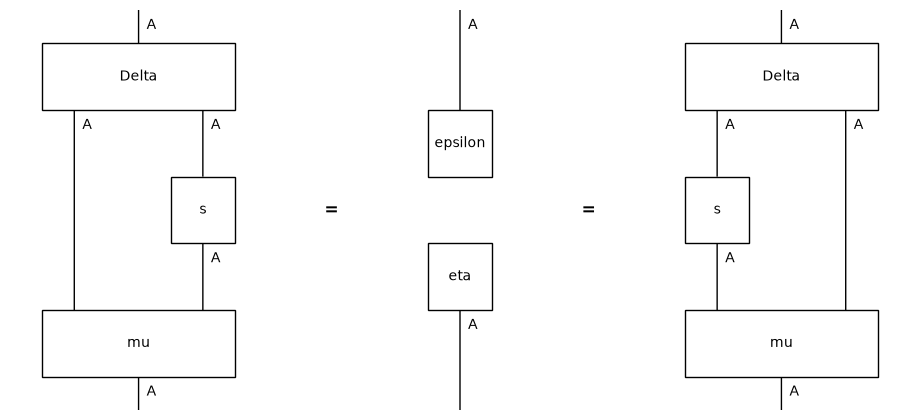

In [3]:
left = Delta >> (I @ s) >> mu
right = Delta >> (s @ I) >> mu
unit_counit = epsilon >> eta
Equation(left, unit_counit, right).draw(figsize=(9, 4))
for name, diagram in [('left antipode composite', left), ('unit after counit', unit_counit), ('right antipode composite', right)]:
    print(name, ':', diagram.dom, '->', diagram.cod)
    print('Computed array:\n', F(diagram).array)
    print('Matches unit after counit:', F(diagram) == F(unit_counit))

**Translation note.** The typed right antipode composite includes `Delta`, as in (3.41), the diagram (3.42) and the basis calculation (3.43). A general Hopf-algebra rewrite proof is a temporary placeholder.